In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [ ]:
import pandas as pd
import io
df = pd.read_csv("clv_data.csv")
df.head()

,Unnamed: 0,id,age,gender,income,days_on_platform,city,purchases
0,0,0,NaN,Male,126895,14.0,San Francisco,0
1,1,1,NaN,Male,161474,14.0,Tokyo,0
2,2,2,24.0,Male,104723,34.0,London,1
3,3,3,29.0,Male,43791,28.0,London,2
4,4,4,18.0,Female,132181,26.0,London,2


In [ ]:
df.shape

(5000, 8)

In [ ]:
df.columns

Index(['Unnamed: 0', 'id', 'age', 'gender', 'income', 'days_on_platform',
       'city', 'purchases'],
      dtype='object')

In [ ]:
df.describe()

,Unnamed: 0,id,age,income,days_on_platform,purchases
count,5000.000000,5000.000000,2554.000000,5000.000000,4859.000000,5000.000000
mean,2499.500000,2499.500000,30.202036,79593.336200,24.389998,1.101000
std,1443.520003,1443.520003,12.129439,60304.056095,18.153388,1.181473
min,0.000000,0.000000,10.000000,4.000000,1.000000,0.000000
25%,1249.750000,1249.750000,19.000000,32752.500000,10.000000,0.000000
50%,2499.500000,2499.500000,30.000000,65989.000000,21.000000,1.000000
75%,3749.250000,3749.250000,41.000000,115406.500000,35.000000,2.000000
max,4999.000000,4999.000000,50.000000,388572.000000,111.000000,6.000000


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
id,0
age,2446
gender,0
income,0
days_on_platform,141
city,0
purchases,0


<function matplotlib.pyplot.show(close=None, block=None)>

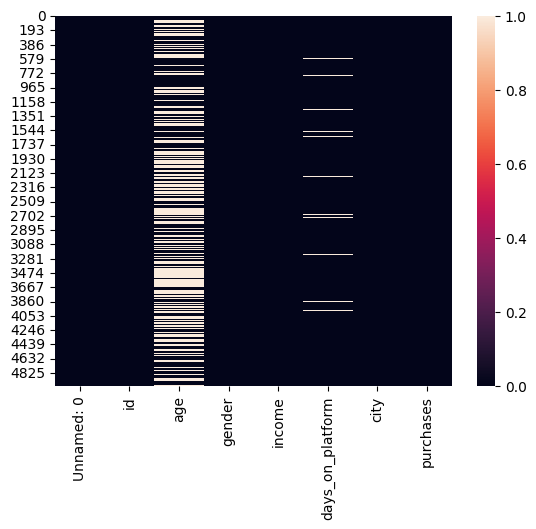

In [ ]:
sns.heatmap(df.isnull())
plt.show

In [ ]:
df["age"] = df["age"].fillna(df["age"].median())

In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
id,0
age,0
gender,0
income,0
days_on_platform,141
city,0
purchases,0


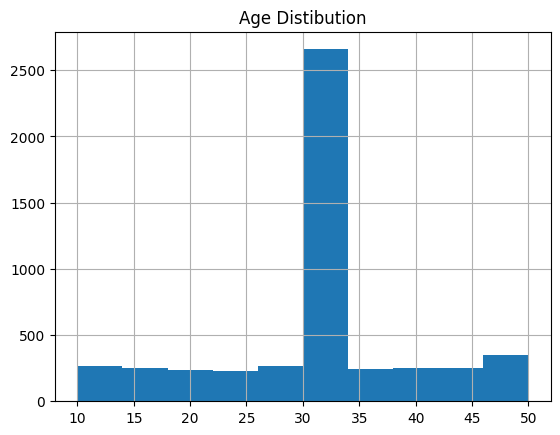

In [ ]:
df["age"].hist(bins=10)
plt.title("Age Distibution")
plt.show()

In [ ]:
df["days_on_platform"] = df["days_on_platform"].fillna(df["days_on_platform"].mean())

In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
id,0
age,0
gender,0
income,0
days_on_platform,0
city,0
purchases,0


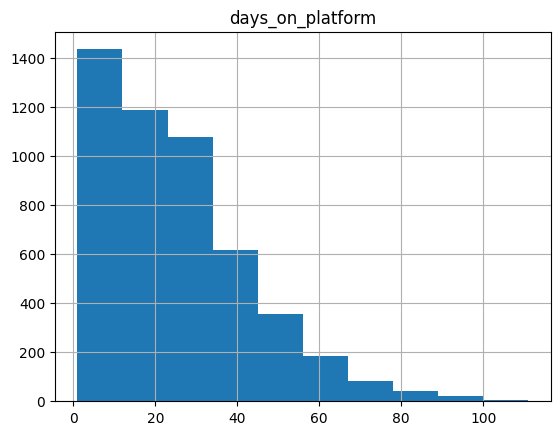

In [ ]:
df["days_on_platform"].hist(bins=10)
plt.title("days_on_platform")
plt.show()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
numeric_cols = df.select_dtypes(include='number').columns
for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3- Q1
  lower = Q1- 1.5 * IQR
  upper = Q3 + 1.5 * IQR
  outliers = df[(df[col] < lower) | (df[col] > upper)]
  print(f"{col}")
  print(f"Lower Limit : {lower}")
  print(f"Upper Limit : {upper}")
  print(f"No. of Outliers : {len(outliers)}")
  print("-"*40)

Unnamed: 0
Lower Limit : -2499.5
Upper Limit : 7498.5
No. of Outliers : 0
----------------------------------------
id
Lower Limit : -2499.5
Upper Limit : 7498.5
No. of Outliers : 0
----------------------------------------
age
Lower Limit : 28.5
Upper Limit : 32.5
No. of Outliers : 2345
----------------------------------------
income
Lower Limit : -91228.5
Upper Limit : 239387.5
No. of Outliers : 77
----------------------------------------
days_on_platform
Lower Limit : -26.0
Upper Limit : 70.0
No. of Outliers : 104
----------------------------------------
purchases
Lower Limit : -3.0
Upper Limit : 5.0
No. of Outliers : 10
----------------------------------------


In [ ]:
# # Age
# # Keep
# # Income
# df["income"] = df["income"].clip(lower, upper)
# # Days
# df["days_on_platform"] = df["days_on_platform"].clip(lower, upper)

In [ ]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    if col in ["id", "Unnamed: 0"]:
        continue

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

age: 2345 outliers
income: 77 outliers
days_on_platform: 104 outliers
purchases: 10 outliers


In [ ]:
Q1 = df["income"].quantile(0.25)
Q3 = df["income"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["income"] = df["income"].clip(lower, upper)

In [ ]:
print(df["age"].min(),df["age"].max())
print(df["income"].min())
print(df["days_on_platform"].min())
print(df["purchases"].min())

10.0 50.0
4.0
1.0
0


In [ ]:
print(df["gender"].unique())
print(df["city"].unique())

['Male' 'Female']
['San Francisco' 'Tokyo' 'London' 'New York City' 'Miami']


In [ ]:
print(df.columns)

Index(['Unnamed: 0', 'id', 'age', 'gender', 'income', 'days_on_platform',
       'city', 'purchases'],
      dtype='object')


In [ ]:
df =pd.get_dummies(df, columns=["gender", "city"],drop_first=True)
print(df.columns)

Index(['Unnamed: 0', 'id', 'age', 'income', 'days_on_platform', 'purchases',
       'gender_Male', 'city_Miami', 'city_New York City', 'city_San Francisco',
       'city_Tokyo'],
      dtype='object')


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler =StandardScaler()
cols= ["age","income", "days_on_platform","purchases"]
df[cols]= scaler.fit_transform(df[cols])
print(df.head())

   Unnamed: 0  id       age    income  days_on_platform  purchases  \
0           0   0 -0.011906  0.817507         -0.580649  -0.931981   
1           1   1 -0.011906  1.408377         -0.580649  -0.931981   
2           2   2 -0.704121  0.438642          0.537059  -0.085495   
3           3   3 -0.127275 -0.602535          0.201747   0.760991   
4           4   4 -1.396335  0.907832          0.089976   0.760991   

   gender_Male  city_Miami  city_New York City  city_San Francisco  city_Tokyo  
0         True       False               False                True       False  
1         True       False               False               False        True  
2         True       False               False               False       False  
3         True       False               False               False       False  
4        False       False               False               False       False  


In [ ]:
print(df[cols].describe())

                age        income  days_on_platform     purchases
count  5.000000e+03  5.000000e+03      5.000000e+03  5.000000e+03
mean  -1.108447e-16  8.597567e-17     -1.200817e-16  2.131628e-17
std    1.000100e+00  1.000100e+00      1.000100e+00  1.000100e+00
min   -2.319288e+00 -1.350747e+00     -1.307160e+00 -9.319809e-01
25%   -1.190609e-02 -7.911559e-01     -8.041912e-01 -9.319809e-01
50%   -1.190609e-02 -2.232261e-01     -1.894515e-01 -8.549507e-02
75%    1.034630e-01  6.211971e-01      5.370591e-01  7.609907e-01
max    2.295475e+00  2.739727e+00      4.840237e+00  4.146934e+00


In [ ]:
df.drop(columns=["Unnamed: 0","id"], inplace=True)

In [ ]:
bool_cols =df.select_dtypes(include="bool").columns
df[bool_cols] =df[bool_cols].astype(int)
df.head()

,age,income,days_on_platform,purchases,gender_Male,city_Miami,city_New York City,city_San Francisco,city_Tokyo
0,-0.011906,0.817507,-0.580649,-0.931981,1,0,0,1,0
1,-0.011906,1.408377,-0.580649,-0.931981,1,0,0,0,1
2,-0.704121,0.438642,0.537059,-0.085495,1,0,0,0,0
3,-0.127275,-0.602535,0.201747,0.760991,1,0,0,0,0
4,-1.396335,0.907832,0.089976,0.760991,0,0,0,0,0


In [ ]:
print(df.info())
print(df.isnull().sum())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 5000 non-null   float64
 1   income              5000 non-null   float64
 2   days_on_platform    5000 non-null   float64
 3   purchases           5000 non-null   float64
 4   gender_Male         5000 non-null   int64  
 5   city_Miami          5000 non-null   int64  
 6   city_New York City  5000 non-null   int64  
 7   city_San Francisco  5000 non-null   int64  
 8   city_Tokyo          5000 non-null   int64  
dtypes: float64(4), int64(5)
memory usage: 351.7 KB
None
age                   0
income                0
days_on_platform      0
purchases             0
gender_Male           0
city_Miami            0
city_New York City    0
city_San Francisco    0
city_Tokyo            0
dtype: int64
                age        income  days_on_platform     purchases  \
